# Heart Disease Prediction Using Machine Learning

## Project Overview

This project applies machine learning techniques to predict the presence of heart disease using patient health-related features. It covers data exploration, preprocessing, model training, and performance evaluation.

## Objectives

- Explore and understand the dataset.
- Prepare numerical and categorical features for machine learning.
- Train and compare multiple classification algorithms.
- Evaluate model performance using classification metrics and ROC-AUC.
- Save the selected trained model for future predictions.

## Machine Learning Workflow

1. Data loading and inspection
2. Exploratory Data Analysis (EDA)
3. Data preprocessing
4. Train-test split
5. Model training and comparison
6. Model evaluation and validation
7. Saving the selected model

## Technologies Used

Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, and Jupyter Notebook.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import os
import warnings

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay
)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully.")


All libraries imported successfully.


In [2]:
# Load the two datasets
train_values = pd.read_csv("values.csv")
train_labels = pd.read_csv("labels.csv")

# Check dataset dimensions
print("Training features shape:", train_values.shape)
print("Training labels shape:", train_labels.shape)

# Display the first five rows
display(train_values.head())
display(train_labels.head())

Training features shape: (180, 14)
Training labels shape: (180, 2)


,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0


,patient_id,heart_disease_present
0,0z64un,0
1,ryoo3j,0
2,yt1s1x,1
3,l2xjde,1
4,oyt4ek,0


In [3]:
# Combine the datasets  
# Join patient information with its target label using patient_id.

print("Current folder:", os.getcwd())

values = pd.read_csv("values.csv")
labels = pd.read_csv("labels.csv")

print("Values loaded:", values.shape)
print("Labels loaded:", labels.shape)

display(values.head())
display(labels.head())


Current folder: C:\Users\prana\Project For ML\Heart Disease Prediction
Values loaded: (180, 14)
Labels loaded: (180, 2)


,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0


,patient_id,heart_disease_present
0,0z64un,0
1,ryoo3j,0
2,yt1s1x,1
3,l2xjde,1
4,oyt4ek,0


In [4]:
# Display the first five rows


print("Features dataset:")
display(values.head())

print("Labels dataset:")
display(labels.head())

Features dataset:


,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0


Labels dataset:


,patient_id,heart_disease_present
0,0z64un,0
1,ryoo3j,0
2,yt1s1x,1
3,l2xjde,1
4,oyt4ek,0


In [5]:
# Check dataset dimensions

print("Features dataset shape:", values.shape)
print("Labels dataset shape:", labels.shape)

print("\nFeature columns:")
print(values.columns.tolist())

print("\nLabel columns:")
print(labels.columns.tolist())


Features dataset shape: (180, 14)
Labels dataset shape: (180, 2)

Feature columns:
['patient_id', 'slope_of_peak_exercise_st_segment', 'thal', 'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels', 'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age', 'max_heart_rate_achieved', 'exercise_induced_angina']

Label columns:
['patient_id', 'heart_disease_present']


In [6]:
# Merge the datasets

data = pd.merge(values, labels, on="patient_id")

print("Combined dataset:", data.shape)
display(data.head())


Combined dataset: (180, 15)


,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


In [7]:
# Understand the dataset

print("Dataset information:")
data.info()

print("\nStatistical summary:")
display(data.describe(include="all").T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    object 
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    object 
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels                     180 non-null    int64  
 6   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 7   resting_ekg_results                   180 non-null    int64  
 8   serum_cholesterol_mg_per_dl           180 non-null    int64  
 9   oldpeak_eq_st_depression              180 non-null    float64
 10  sex                                   180 non-null    int64  
 11

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
patient_id,180,180,0z64un,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
slope_of_peak_exercise_st_segment,180.0,NaN,NaN,NaN,1.55,0.618838,1.0,1.0,1.0,2.0,3.0
thal,180,3,normal,98,NaN,NaN,NaN,NaN,NaN,NaN,NaN
resting_blood_pressure,180.0,NaN,NaN,NaN,131.311111,17.010443,94.0,120.0,130.0,140.0,180.0
chest_pain_type,180.0,NaN,NaN,NaN,3.155556,0.938454,1.0,3.0,3.0,4.0,4.0
num_major_vessels,180.0,NaN,NaN,NaN,0.694444,0.969347,0.0,0.0,0.0,1.0,3.0
fasting_blood_sugar_gt_120_mg_per_dl,180.0,NaN,NaN,NaN,0.161111,0.368659,0.0,0.0,0.0,0.0,1.0
resting_ekg_results,180.0,NaN,NaN,NaN,1.05,0.998742,0.0,0.0,2.0,2.0,2.0
serum_cholesterol_mg_per_dl,180.0,NaN,NaN,NaN,249.211111,52.717969,126.0,213.75,245.5,281.25,564.0
oldpeak_eq_st_depression,180.0,NaN,NaN,NaN,1.01,1.121357,0.0,0.0,0.8,1.6,6.2


In [8]:
# Check missing values and duplicates

print("Missing values in each column:")
display(data.isnull().sum())

print("Total missing values:", data.isnull().sum().sum())
print("Duplicate rows:", data.duplicated().sum())
print("Duplicate patient IDs:", data["patient_id"].duplicated().sum())

Missing values in each column:


patient_id                              0
slope_of_peak_exercise_st_segment       0
thal                                    0
resting_blood_pressure                  0
chest_pain_type                         0
num_major_vessels                       0
fasting_blood_sugar_gt_120_mg_per_dl    0
resting_ekg_results                     0
serum_cholesterol_mg_per_dl             0
oldpeak_eq_st_depression                0
sex                                     0
age                                     0
max_heart_rate_achieved                 0
exercise_induced_angina                 0
heart_disease_present                   0
dtype: int64

Total missing values: 0
Duplicate rows: 0
Duplicate patient IDs: 0


In [9]:
# Check the target variable

target = "heart_disease_present"

print("Target value counts:")
display(data[target].value_counts(dropna=False))

print("\nTarget distribution in percentages:")
display((data[target].value_counts(normalize=True, dropna=False) * 100).round(2))

Target value counts:


heart_disease_present
0    100
1     80
Name: count, dtype: int64


Target distribution in percentages:


heart_disease_present
0    55.56
1    44.44
Name: proportion, dtype: float64

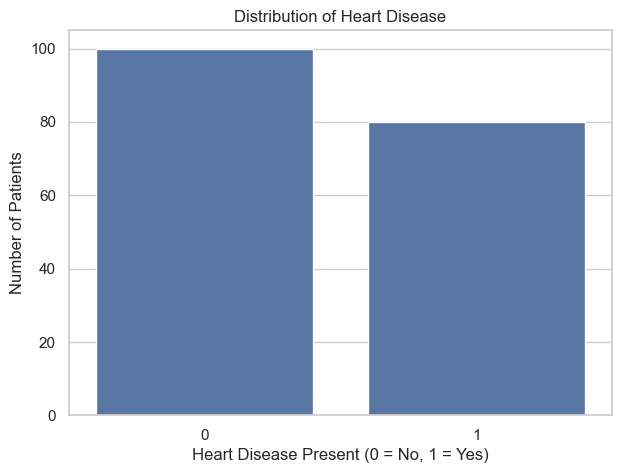

In [10]:
# Visualize target distribution

plt.figure(figsize=(7, 5))
sns.countplot(data=data, x="heart_disease_present")
plt.title("Distribution of Heart Disease")
plt.xlabel("Heart Disease Present (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")
plt.show()

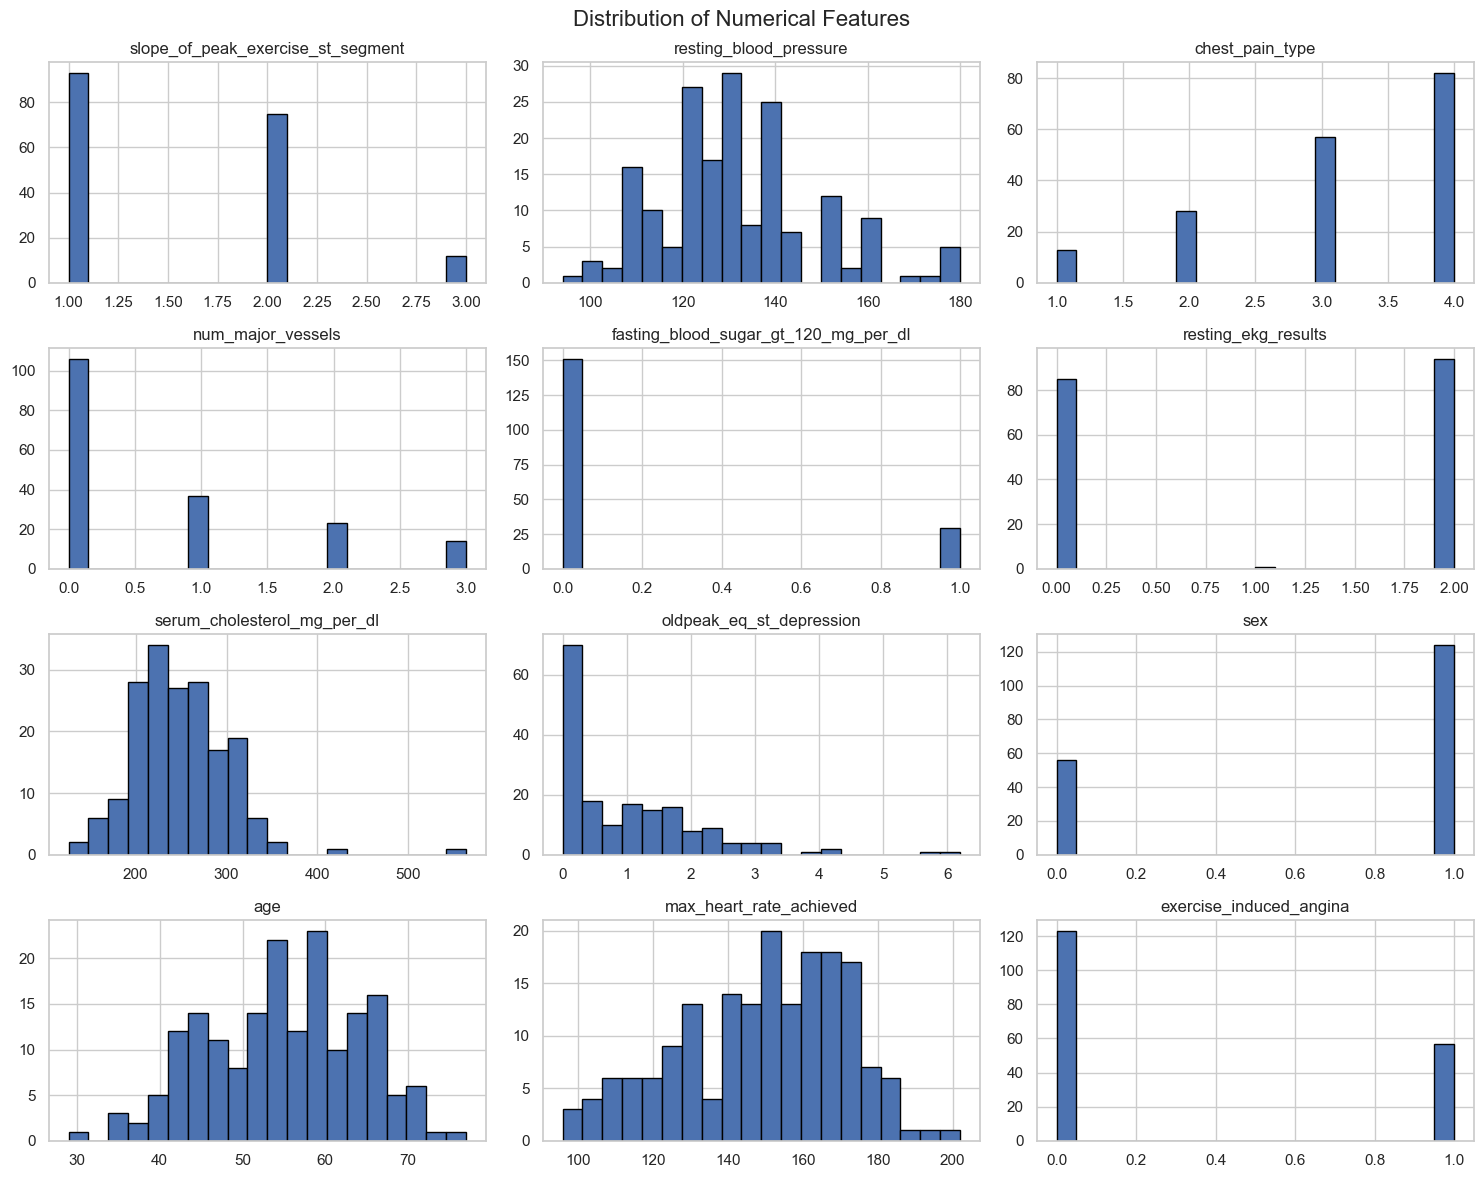

In [11]:
# Analyze numerical features

numeric_data = data.select_dtypes(include=np.number)

numeric_features = numeric_data.drop(
    columns=["patient_id", "heart_disease_present"],
    errors="ignore"
)

numeric_features.hist(figsize=(15, 12), bins=20, edgecolor="black")
plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

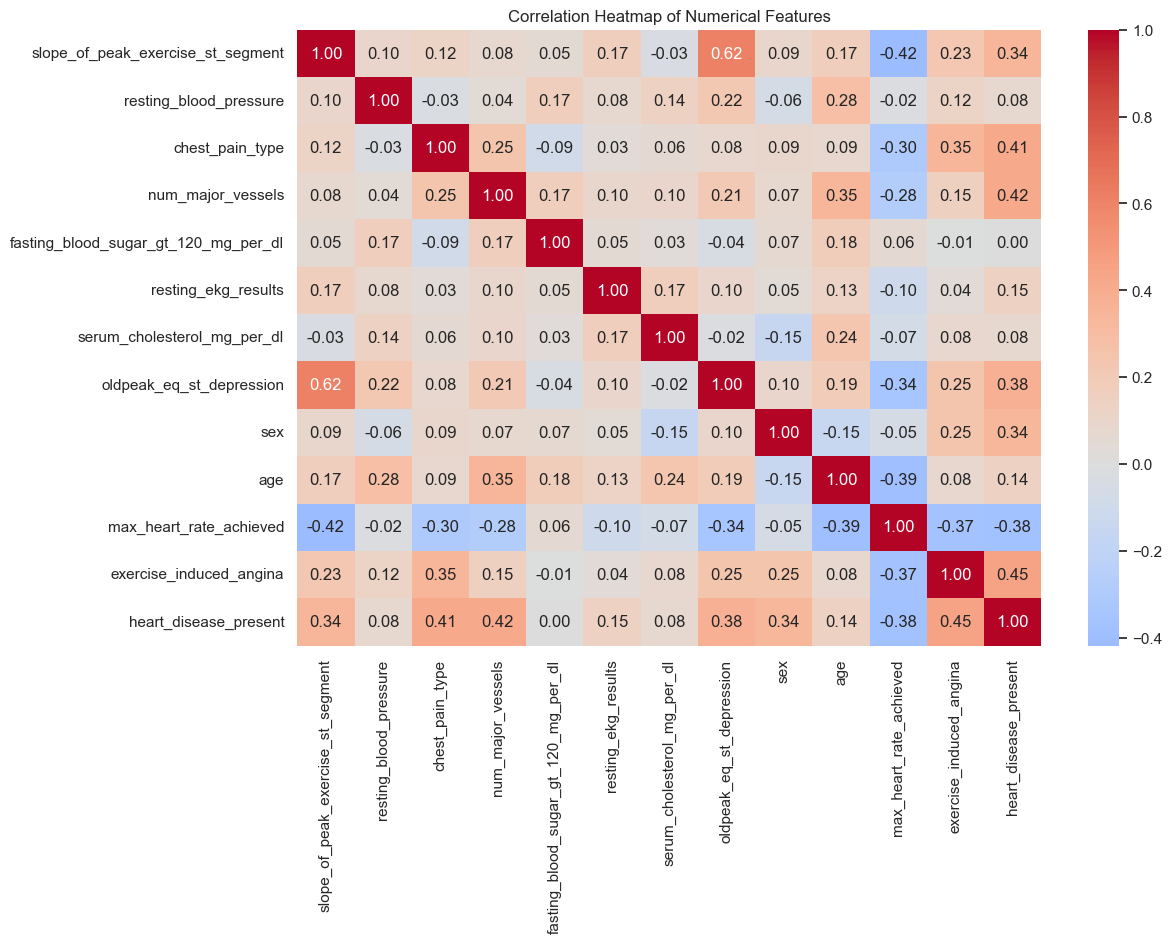

In [12]:
# Correlation heatmap

plt.figure(figsize=(12, 8))

correlation_data = data.select_dtypes(include=np.number).drop(
    columns=["patient_id"], errors="ignore"
)

sns.heatmap(
    correlation_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

In [13]:
# Analyze categorical features

categorical_columns = data.select_dtypes(exclude=np.number).columns.tolist()

print("Categorical columns:", categorical_columns)

for column in categorical_columns:
    print(f"\nValue counts for {column}:")
    display(data[column].value_counts(dropna=False))

Categorical columns: ['patient_id', 'thal']

Value counts for patient_id:


patient_id
0z64un    1
sqddbc    1
lpub9d    1
bv01fp    1
9dqkpy    1
         ..
m2a4i9    1
pwigd8    1
qwapdq    1
4sd1xn    1
2nx10r    1
Name: count, Length: 180, dtype: int64


Value counts for thal:


thal
normal               98
reversible_defect    74
fixed_defect          8
Name: count, dtype: int64

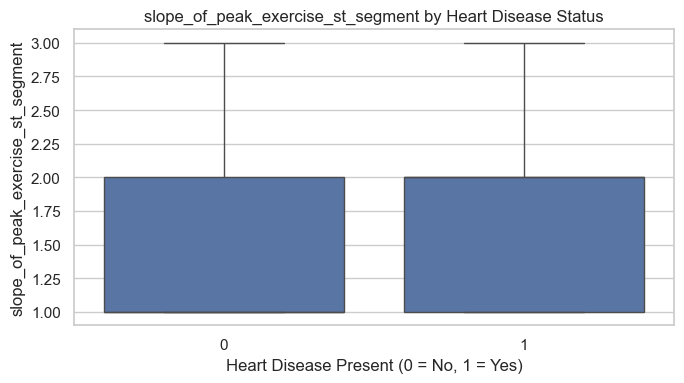

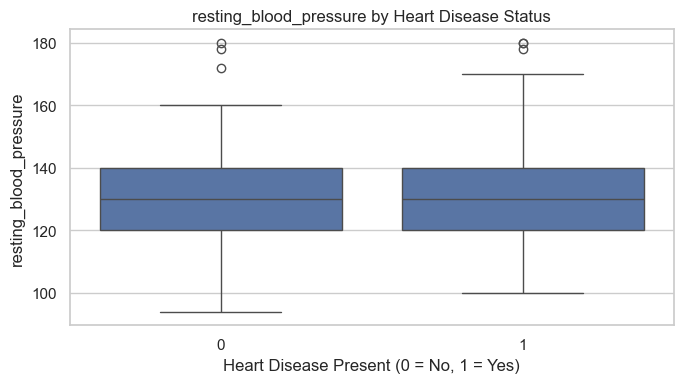

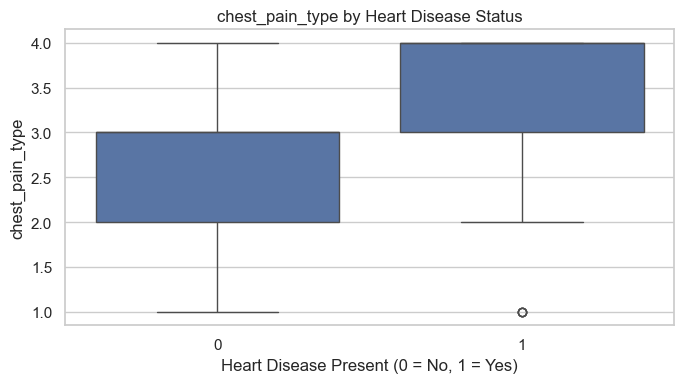

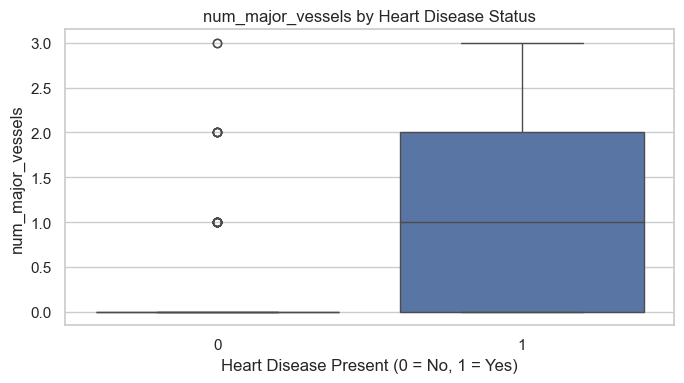

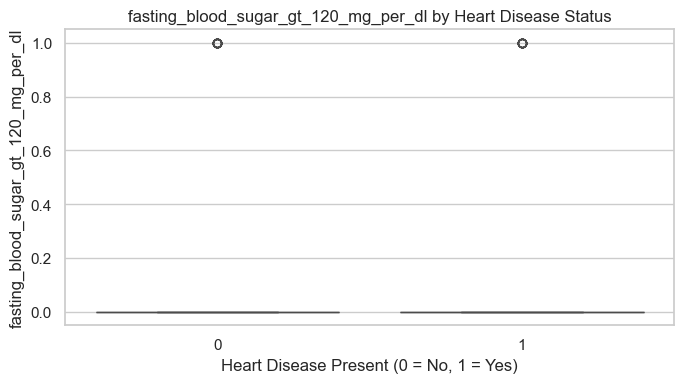

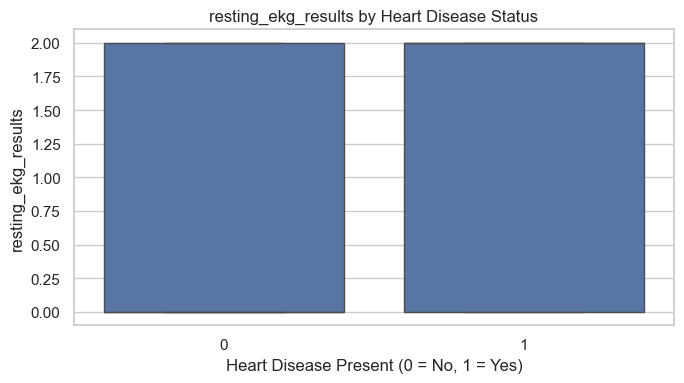

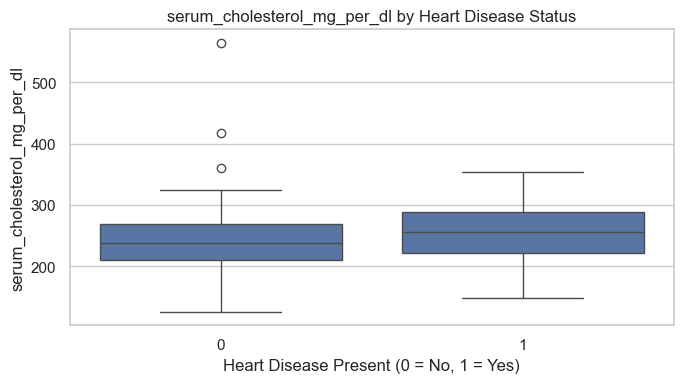

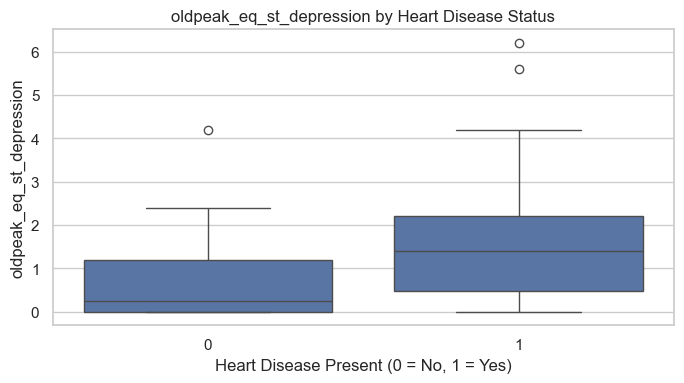

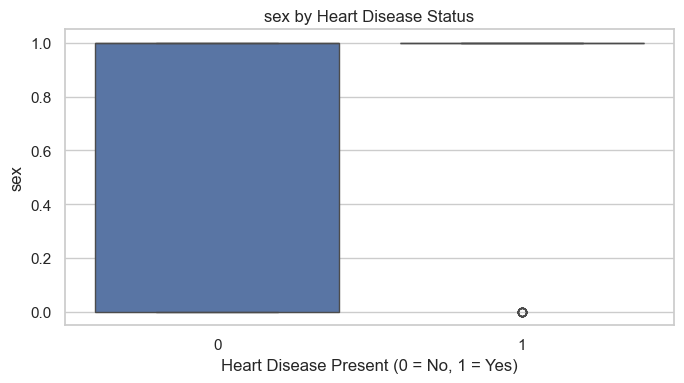

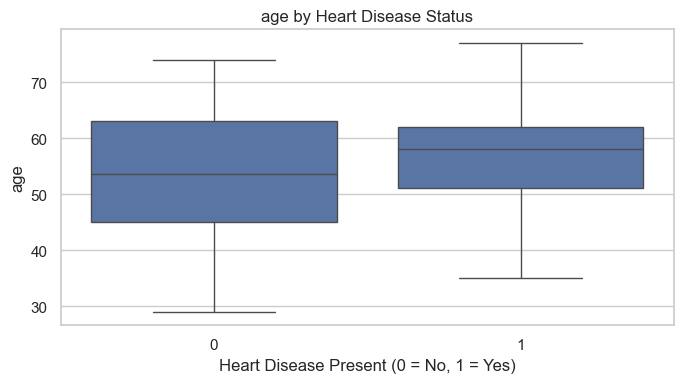

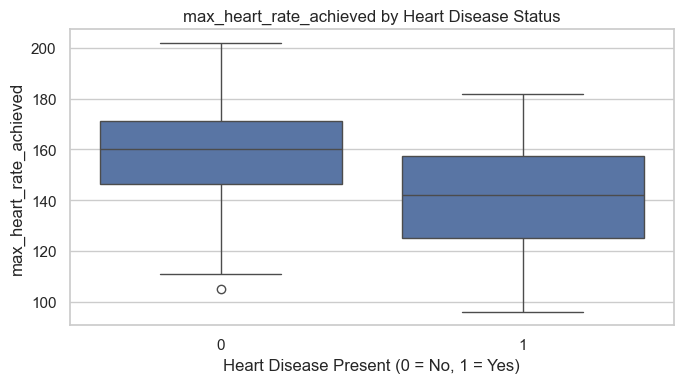

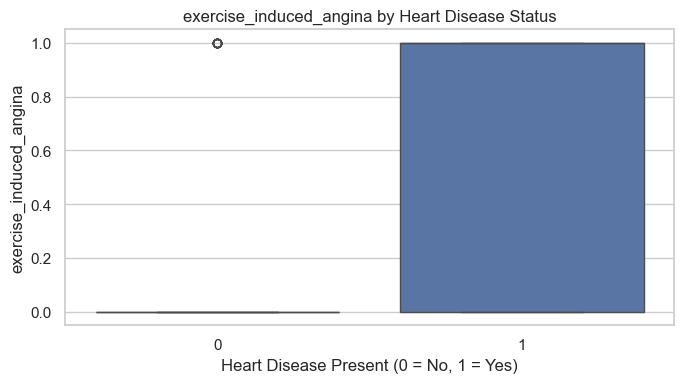

In [14]:
# Compare features with the target

for column in numeric_features.columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=data, x=target, y=column)
    plt.title(f"{column} by Heart Disease Status")
    plt.xlabel("Heart Disease Present (0 = No, 1 = Yes)")
    plt.tight_layout()
    plt.show()

In [15]:
# Prepare features and target

X = data.drop(columns=["patient_id", "heart_disease_present"])
y = data["heart_disease_present"]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Feature matrix shape: (180, 13)
Target vector shape: (180,)

Feature columns:
['slope_of_peak_exercise_st_segment', 'thal', 'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels', 'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age', 'max_heart_rate_achieved', 'exercise_induced_angina']


In [16]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (144, 13)
Testing features: (36, 13)
Training target: (144,)
Testing target: (36,)


In [17]:
# Identify numerical and categorical columns
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

# Preprocess numerical features
numeric_transformer = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

# Preprocess categorical features
categorical_transformer = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore")
)

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols)
    ]
)

print("Preprocessor created successfully!")
print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

Preprocessor created successfully!
Numerical columns: ['slope_of_peak_exercise_st_segment', 'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels', 'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age', 'max_heart_rate_achieved', 'exercise_induced_angina']
Categorical columns: ['thal']


In [18]:
# Create the preprocessing pipeline

models = {
    "Logistic Regression": make_pipeline(
        preprocessor,
        LogisticRegression(max_iter=1000, random_state=42)
    ),

    "Random Forest": make_pipeline(
        preprocessor,
        RandomForestClassifier(
            n_estimators=200,
            random_state=42
        )
    ),

    "Gradient Boosting": make_pipeline(
        preprocessor,
        GradientBoostingClassifier(random_state=42)
    )
}

print("Models created:")
for model_name in models:
    print("-", model_name)


Models created:
- Logistic Regression
- Random Forest
- Gradient Boosting


In [19]:
# Train the models and compare accuracy

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    print(f"{name} Accuracy: {accuracy:.3f}")

Logistic Regression Accuracy: 0.806
Random Forest Accuracy: 0.889
Gradient Boosting Accuracy: 0.917


In [20]:
# Create the model comparison report

results = []

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("ROC-AUC", ascending=False)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Gradient Boosting,0.917,0.842,1.000,0.914,0.956
0,Logistic Regression,0.806,0.765,0.812,0.788,0.941
1,Random Forest,0.889,0.800,1.000,0.889,0.941


In [21]:
# Select the best model

best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]

print("Best model based on test ROC-AUC:", best_name)
print(
    "Best model ROC-AUC:",
    round(roc_auc_score(
        y_test, best_model.predict_proba(X_test)[:, 1]
    ), 3)
)

Best model based on test ROC-AUC: Gradient Boosting
Best model ROC-AUC: 0.956


In [22]:
# Save the selected trained model
with open("heart_model.pkl", "wb") as file:
    pickle.dump(best_model, file)

print("Model saved successfully as heart_model.pkl")

Model saved successfully as heart_model.pkl


In [23]:
# Classification report

best_predictions = best_model.predict(X_test)

print("Classification Report for", best_name)
print(
    classification_report(
        y_test,
        best_predictions,
        target_names=["No Heart Disease", "Heart Disease"],
        zero_division=0
    )
)

Classification Report for Gradient Boosting
                  precision    recall  f1-score   support

No Heart Disease       1.00      0.85      0.92        20
   Heart Disease       0.84      1.00      0.91        16

        accuracy                           0.92        36
       macro avg       0.92      0.93      0.92        36
    weighted avg       0.93      0.92      0.92        36



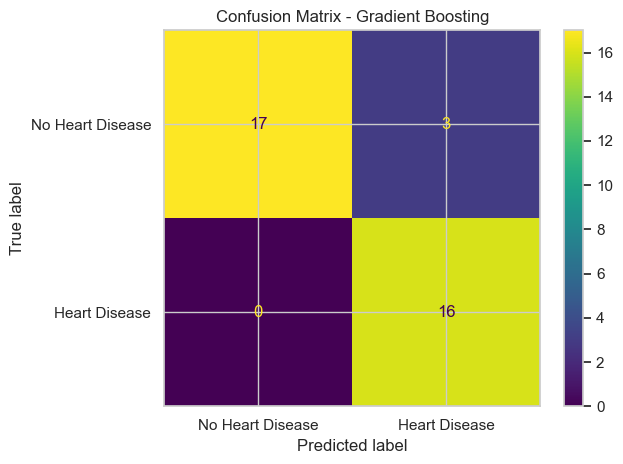

In [24]:
# Confusion matrix

ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    display_labels=["No Heart Disease", "Heart Disease"]
)

plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.show()


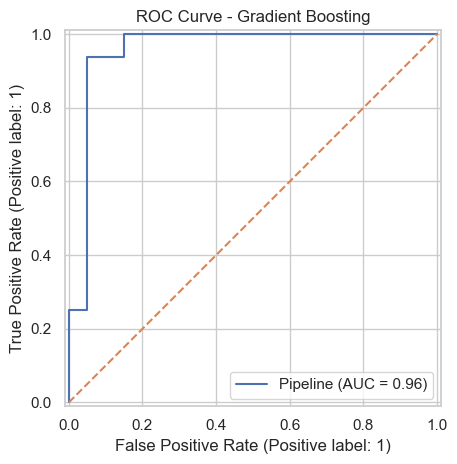

In [25]:
# ROC curve

RocCurveDisplay.from_estimator(best_model, X_test, y_test)

plt.title(f"ROC Curve - {best_name}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.tight_layout()
plt.show()

In [26]:
# Cross-validation

cv_scores = cross_val_score(
    best_model,
    X,
    y,
    cv=5,
    scoring="roc_auc"
)

print("Cross-validation ROC-AUC scores:", np.round(cv_scores, 3))
print("Mean cross-validation ROC-AUC:", round(cv_scores.mean(), 3))
print("Standard deviation:", round(cv_scores.std(), 3))

Cross-validation ROC-AUC scores: [0.841 0.919 0.925 0.784 0.841]
Mean cross-validation ROC-AUC: 0.862
Standard deviation: 0.053


In [27]:
# Load the saved model and test it

with open("heart_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

sample = X_test.iloc[[0]]

prediction = loaded_model.predict(sample)[0]
probability = loaded_model.predict_proba(sample)[0][1]

print("Predicted class:", prediction)
print("Predicted probability of heart disease:", round(probability, 3))

if prediction == 1:
    print("The model predicts a higher likelihood of heart disease.")
else:
    print("The model predicts a lower likelihood of heart disease.")


Predicted class: 0
Predicted probability of heart disease: 0.102
The model predicts a lower likelihood of heart disease.



## Data Analysis Findings

1. The feature and label datasets were combined using `patient_id`.
2. The target variable, `heart_disease_present`, represents whether heart disease is present.
3. Numerical and categorical features were examined separately.
4. The target distribution and feature distributions were visualized.
5. A correlation heatmap was used to explore relationships between numerical variables.
6. The dataset was split into training and testing sets to evaluate model performance on unseen records.
7. Missing values, duplicates, and data types were checked before model training.

The actual distribution, missing-value counts, and relationships should be interpreted from the outputs produced above.



## Data Challenges and Techniques Used

### 1. Combining multiple datasets
The feature dataset and label dataset were stored separately. They were merged using `patient_id`.

### 2. Mixed data types
The dataset contains numerical and categorical features. A `ColumnTransformer` was used to process each type separately.

### 3. Missing values
Missing values were checked. Numerical missing values are handled using median imputation, while categorical missing values are handled using most-frequent imputation.

### 4. Categorical encoding
Text categories were converted into numerical representations using `OneHotEncoder`.

### 5. Feature scaling
Numerical features were standardized using `StandardScaler` for models that benefit from scaled inputs.

### 6. Model evaluation
Accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix were used to compare the models.

### 7. Generalization and limitations
Cross-validation was used as an additional evaluation technique. Performance estimates from a single small test split can vary, and further independent validation is necessary.



## Recommendations for Hospitals

1. **Improve early screening:** Establish appropriate screening and assessment processes based on patient history, symptoms, and clinically recognized risk factors.
2. **Use ML only as decision support:** Evaluate whether a validated model can assist qualified healthcare professionals in identifying patients who may need further assessment.
3. **Prioritize clinical review:** Use validated risk assessment pathways to determine which patients need additional tests or follow-up.
4. **Encourage preventive care:** Promote appropriate physical activity, balanced nutrition, smoking cessation, and regular medical check-ups.
5. **Monitor high-risk patients:** Develop follow-up plans based on clinical guidelines and individual patient needs.
6. **Maintain data quality and privacy:** Ensure patient information is accurate, securely stored, and handled under applicable privacy requirements.
7. **Validate before deployment:** Test the model on independent, representative patient populations and evaluate false negatives, false positives, calibration, and performance across demographic groups.

### Important limitation
This project uses a limited dataset and is an educational exercise. The model should not be used to diagnose patients or make treatment decisions without appropriate clinical validation, regulatory review where applicable, and medical oversight.



## Conclusion

This project demonstrates a machine learning workflow for heart disease prediction, including data merging, exploratory data analysis, preprocessing, model training, evaluation, and model saving.

Logistic Regression, Random Forest, and Gradient Boosting were compared using multiple evaluation metrics. The model with the highest test ROC-AUC was selected for further examination, with cross-validation providing an additional performance estimate.

The findings may help illustrate how predictive analytics could support research into early detection. However, the model's performance must be independently validated before any clinical use. Predictions from this project are not a substitute for professional medical assessment.


In [28]:
# Display model comparison results
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Gradient Boosting,0.9167,0.8421,1.0000,0.9143,0.9562
0,Logistic Regression,0.8056,0.7647,0.8125,0.7879,0.9406
1,Random Forest,0.8889,0.8000,1.0000,0.8889,0.9406
